# IEEE PUA - Linear Regression Task

**Task 1 | Machine Learning Track**

**Goal:** predict a continuous value using Linear Regression and check how well the model performs on unseen data.

For this task, I used the Diabetes dataset available in scikit-learn. It contains 442 samples and 10 numeric input features. The target is a quantitative measure of disease progression one year after baseline. I will use **BMI** as the input feature so the regression line can be plotted easily.

The dataset is included as `diabetes_regression.csv`, so the notebook does not need an internet connection. The features are already standardized in the source dataset.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams["figure.figsize"] = (7, 4.5)

## 2. Load the dataset

In [2]:
df = pd.read_csv("diabetes_regression.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  disease_progression  442 non-null    int64  
dtypes: float64(10), int64(1)
memory usage: 38.1 KB


In [4]:
df.describe().round(2)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
count,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00
mean,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,152.13
std,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,77.09
min,-0.11,-0.04,-0.09,-0.11,-0.13,-0.12,-0.10,-0.08,-0.13,-0.14,25.00
25%,-0.04,-0.04,-0.03,-0.04,-0.03,-0.03,-0.04,-0.04,-0.03,-0.03,87.00
50%,0.01,-0.04,-0.01,-0.01,-0.00,-0.00,-0.01,-0.00,-0.00,-0.00,140.50
75%,0.04,0.05,0.03,0.04,0.03,0.03,0.03,0.03,0.03,0.03,211.50
max,0.11,0.05,0.17,0.13,0.15,0.20,0.18,0.19,0.13,0.14,346.00


## 3. Cleaning and preprocessing

First I check for missing values and repeated rows. All the columns are numerical, so no encoding is needed. I will still use a median imputer in the model pipeline in case the input data contains missing values later. It is fitted only on the training set.

In [5]:
print("Missing values by column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("\nShape after removing duplicates:", df.shape)

Missing values by column:
age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3                     0
s4                     0
s5                     0
s6                     0
disease_progression    0
dtype: int64

Duplicate rows: 0

Shape after removing duplicates: (442, 11)


## 4. Exploratory Data Analysis (EDA)

I looked at the distributions of BMI and the target, then plotted how different features are related to the target.

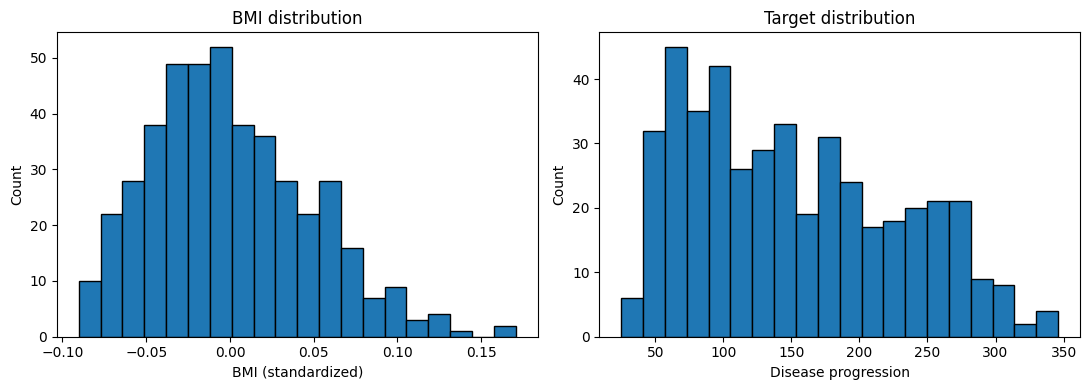

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["bmi"], bins=20, edgecolor="black")
axes[0].set_title("BMI distribution")
axes[0].set_xlabel("BMI (standardized)")
axes[0].set_ylabel("Count")

axes[1].hist(df["disease_progression"], bins=20, edgecolor="black")
axes[1].set_title("Target distribution")
axes[1].set_xlabel("Disease progression")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

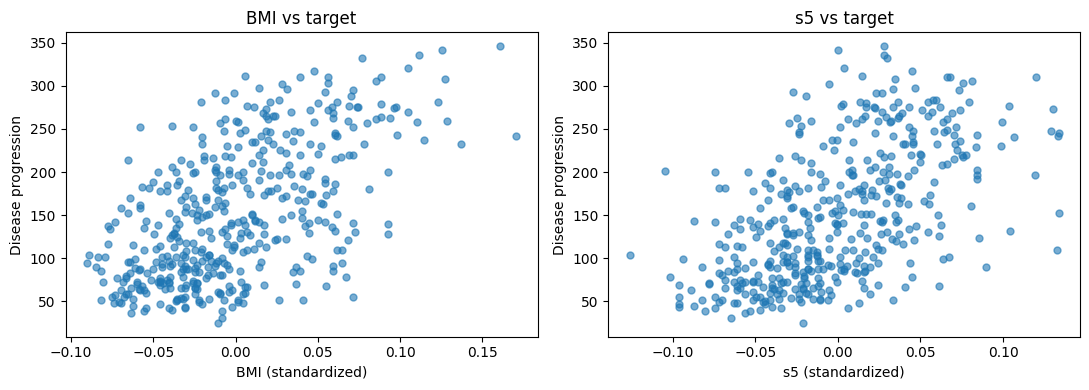

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(df["bmi"], df["disease_progression"], alpha=0.6, s=25)
axes[0].set_title("BMI vs target")
axes[0].set_xlabel("BMI (standardized)")
axes[0].set_ylabel("Disease progression")

axes[1].scatter(df["s5"], df["disease_progression"], alpha=0.6, s=25)
axes[1].set_title("s5 vs target")
axes[1].set_xlabel("s5 (standardized)")
axes[1].set_ylabel("Disease progression")

plt.tight_layout()
plt.show()

Correlation with target:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: disease_progression, dtype: float64


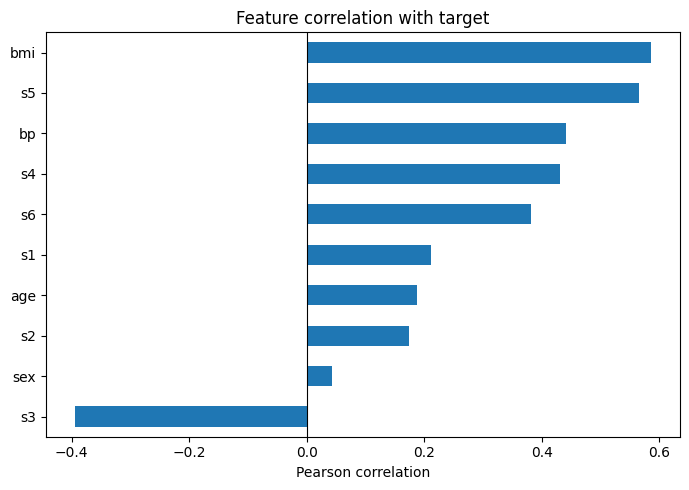

In [8]:
correlations = df.corr(numeric_only=True)["disease_progression"].drop("disease_progression")
print("Correlation with target:")
print(correlations.sort_values(ascending=False).round(3))

correlations.sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Feature correlation with target")
plt.xlabel("Pearson correlation")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**EDA note:** BMI has a positive relationship with the target, although the points are not exactly on a straight line. This suggests that a simple Linear Regression model can capture part of the trend, but probably not all of the variation.

## 5. Split the data

I'll use 80% for training and 20% for testing. `random_state=42` keeps the split the same each time.

In [9]:
X = df[["bmi"]]  # one feature for simple linear regression
y = df["disease_progression"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 353
Testing samples: 89


## 6. Train the Linear Regression model

Simple Linear Regression uses the equation:

\[
\hat y = mx + b
\]

Here, `m` is the coefficient and `b` is the intercept.

In [10]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

slope = model.named_steps["regression"].coef_[0]
intercept = model.named_steps["regression"].intercept_
print(f"Regression equation: y = {slope:.2f} * BMI + {intercept:.2f}")

Regression equation: y = 998.58 * BMI + 152.00


In [11]:
predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
predictions["Absolute_Error"] = abs(predictions["Actual"] - predictions["Predicted"])
predictions.head(10).round(2)

,Actual,Predicted,Absolute_Error
0,219,145.81,73.19
1,70,188.86,118.86
2,202,147.96,54.04
3,230,203.93,26.07
4,111,131.81,20.81
5,84,127.51,43.51
6,242,322.32,80.32
7,272,197.47,74.53
8,94,61.86,32.14
9,96,167.33,71.33


## 7. Evaluate the model

- **MSE:** average squared prediction error (penalizes large errors more).
- **RMSE:** square root of MSE, in the same units as the target.
- **MAE:** average absolute prediction error, also in target units.

All three are better when they are smaller.

In [12]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE : {mae:.2f}")

MSE : 4061.83
RMSE: 63.73
MAE : 52.26


## 8. Plot the regression line

The dots are the actual values. The line represents the model's predictions for different BMI values.

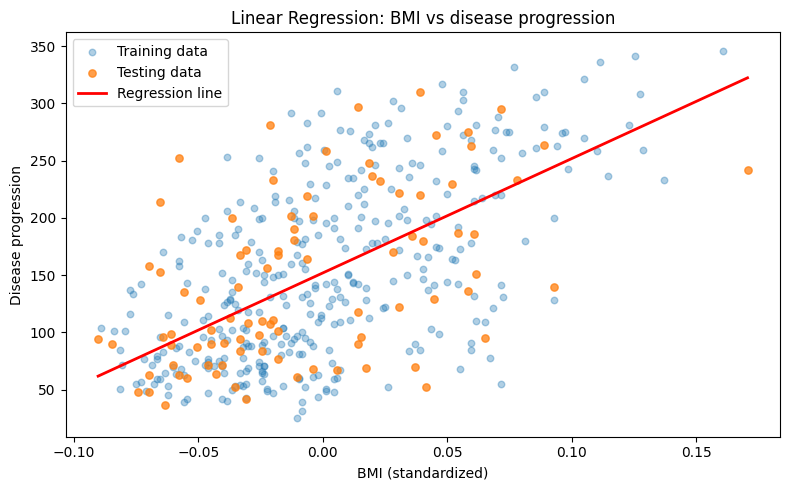

In [13]:
x_line = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 150)})
y_line = model.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(X_train["bmi"], y_train, alpha=0.35, label="Training data", s=22)
plt.scatter(X_test["bmi"], y_test, alpha=0.75, label="Testing data", s=28)
plt.plot(x_line["bmi"], y_line, color="red", linewidth=2, label="Regression line")
plt.title("Linear Regression: BMI vs disease progression")
plt.xlabel("BMI (standardized)")
plt.ylabel("Disease progression")
plt.legend()
plt.tight_layout()
plt.show()

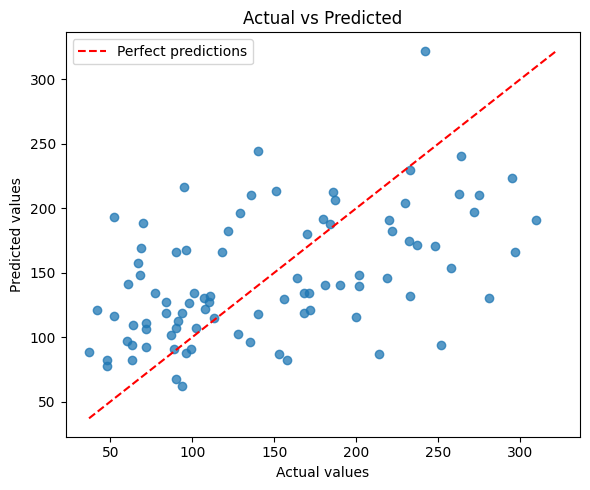

In [14]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.75)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "r--", label="Perfect predictions")
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Conclusion

The model learned an upward trend between BMI and the target, but the actual values are quite spread out around the regression line. This makes sense because disease progression depends on more than just one feature. Using several features might improve performance, but a one-feature model is helpful for understanding simple linear regression and visualizing the fitted line.

**Note:** This is a learning exercise, not a medical prediction tool.